In [3]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import math
from sklearn.metrics import confusion_matrix
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [4]:
print("Tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset_original = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)
train_size = int(0.9 * len(train_dataset_original))  # 54.000 mẫu
val_size = len(train_dataset_original) - train_size   # 6.000 mẫu
# Bước 4: Tạo DataLoader
batch_size = 64
train_dataset, val_dataset = random_split(train_dataset_original, [train_size, val_size])

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

def to_one_hot(y, num_classes=10):
    """Chuyển đổi nhãn indices thành ma trận một-hot dạng Float32 an toàn."""
    one_hot = torch.zeros(y.size(0), num_classes, device=y.device, dtype=torch.float32)
    one_hot[range(y.size(0)), y] = 1.0
    return one_hot


Tải dữ liệu và tính toán thông số chuẩn hóa...
Pixel Mean tính toán động: 0.1307
Pixel Std tính toán động: 0.3081


In [5]:
class SoftmaxClassifier:
    def __init__(self, input_dim=784, num_classes=10, lr=0.001,device='cpu'):
        self.lr = lr
        self.device = device
        # Khởi tạo trọng số Xavier/Glorot bảo vệ gradient ban đầu
        bound = math.sqrt(6.0 / (input_dim + num_classes))
        self.W = (torch.rand(input_dim, num_classes) * 2 * bound) - bound
        self.b = torch.zeros(1, num_classes)
        
        self.cache = {}
        self.dW = None
        self.db = None

    def forward(self, X):
        # Ép phẳng ảnh về dạng (Batch_size, 784)
        X = X.reshape(X.size(0), -1).float()
        
        # Phép tính tuyến tính: Z = XW + b
        Z = torch.matmul(X, self.W) + self.b
        
        # Tinh softmax với ổn định số học: Y_hat = softmax(Z)
        max_z = torch.max(Z, dim=1, keepdim=True)[0]
        exp_z = torch.exp(Z - max_z)
        Y_hat = exp_z / torch.sum(exp_z, dim=1, keepdim=True)
        
        # Lưu cache đồng bộ phục vụ backward pass
        self.cache = {'X': X, 'Y_hat': Y_hat}
        return Y_hat

    def backward(self, Y):
        X = self.cache['X']
        Y_hat = self.cache['Y_hat']
        
        # Tạo ma trận one-hot đồng bộ thiết bị(GPU) và kiểu dữ liệu
        Y_one_hot = to_one_hot(Y, num_classes=Y_hat.size(1))
        
        m = Y.size(0)
        # Tính toán gradient dZ chính xác (đã chuẩn hóa chia m một lần duy nhất)
        dZ = (Y_hat - Y_one_hot) / m

        # Tính toán Gradients cho W và b
        self.dW = torch.matmul(X.t(), dZ)
        self.db = torch.sum(dZ, dim=0, keepdim=True)

    def optimize_step(self):
        # Cập nhật trọng số theo Gradient Descent
        self.W -= self.lr * self.dW
        self.b -= self.lr * self.db



In [6]:
model = SoftmaxClassifier(input_dim=784, num_classes=10, lr=0.001)
epochs = 10

# Khởi tạo các danh sách trống để ghi lại lịch sử các chỉ số
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print("Quá trình huấn luyện mô hình Softmax Classifier...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        Y_hat = model.forward(images)
        
        batch_size = labels.size(0)
        prob_correct_class = Y_hat[range(batch_size), labels]
        loss = -torch.sum(torch.log(prob_correct_class + 1e-9)) / batch_size
        running_loss += loss.item()
        
        _, predicted = torch.max(Y_hat, dim=1)
        total_train += batch_size
        correct_train += (predicted == labels).sum().item()
        
        model.backward(labels)
        model.optimize_step()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- VALIDATION PHASE -----------------
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for val_images, val_labels in val_loader:
            Y_hat_val = model.forward(val_images)

            t_batch_size = val_labels.size(0)
            prob_correct_class_val = Y_hat_val[range(t_batch_size), val_labels]
            val_loss_step = -torch.sum(torch.log(prob_correct_class_val + 1e-9)) / t_batch_size
            running_val_loss += val_loss_step.item()

            _, val_predicted = torch.max(Y_hat_val, dim=1)
            total_val += t_batch_size
            correct_val += (val_predicted == val_labels).sum().item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct_val / total_val

    # LƯU CHỈ SỐ VÀO DANH SÁCH HISTORY
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(val_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Validation ] Loss: {epoch_val_loss:.4f} | Accuracy: {val_accuracy:.2f}%")
    print("-" * 60)

print("Quá trình huấn luyện hoàn tất!")

Quá trình huấn luyện mô hình Softmax Classifier...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 1.2422 | Accuracy: 62.05%
  [Validation ] Loss: 0.7012 | Accuracy: 80.57%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.6135 | Accuracy: 82.55%
  [Validation ] Loss: 0.5418 | Accuracy: 84.77%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.5127 | Accuracy: 85.41%
  [Validation ] Loss: 0.4807 | Accuracy: 86.68%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.4646 | Accuracy: 86.76%
  [Validation ] Loss: 0.4462 | Accuracy: 87.75%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.4353 | Accuracy: 87.54%
  [Validation ] Loss: 0.4241 | Accuracy: 88.33%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.4151 | Accuracy: 88.06%
  [Validation

In [7]:
#Test phase: Đánh giá mô hình trên tập test
running_test_loss = 0.0
correct_test = 0
total_test = 0

all_true_labels = []
all_pred_labels = []

with torch.no_grad():
    for test_images, test_labels in test_loader:
        t_batch_size = test_labels.size(0)
        
        Y_hat_test = model.forward(test_images)
        Y_hat_test_cpu = Y_hat_test.cpu()
        test_labels_cpu = test_labels.cpu()

        prob_correct_class_test = Y_hat_test_cpu[range(t_batch_size), test_labels_cpu]
        test_loss_step = -torch.sum(torch.log(prob_correct_class_test + 1e-9)) / t_batch_size
        running_test_loss += test_loss_step.item()

        _, test_predicted = torch.max(Y_hat_test_cpu, dim=1)
        total_test += t_batch_size
        correct_test += (test_predicted == test_labels_cpu).sum().item()
        
        all_true_labels.extend(test_labels_cpu.numpy().tolist())
        all_pred_labels.extend(test_predicted.numpy().tolist())

# Tính toán các chỉ số trung bình sau khi duyệt qua toàn bộ tập test
final_test_loss = running_test_loss / len(test_loader)
final_test_accuracy = 100 * correct_test / total_test

print(f"\n[KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST]")
print(f"  > Final Test Loss: {final_test_loss:.4f}")
print(f"  > Final Test Accuracy: {final_test_accuracy:.2f}%")


[KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST]
  > Final Test Loss: 0.3491
  > Final Test Accuracy: 90.03%


In [8]:
history['final_test_loss'] = final_test_loss
history['final_test_acc'] = final_test_accuracy

#  Tích hợp dữ liệu mảng nhãn thực tế và dự đoán để vẽ Ma trận nhầm lẫn
history['confusion_matrix'] = {
    'true_labels': all_true_labels,
    'pred_labels': all_pred_labels
}

# Ghi toàn bộ dictionary vào file JSON cấu trúc rõ ràng (indent=4)
json_filename = "softmax_classifier_results.json"
with open(json_filename, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

print(f"Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn vào file thành công!")
print(f"  > Tên file kết quả: '{json_filename}'")

Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn vào file thành công!
  > Tên file kết quả: 'softmax_classifier_results.json'


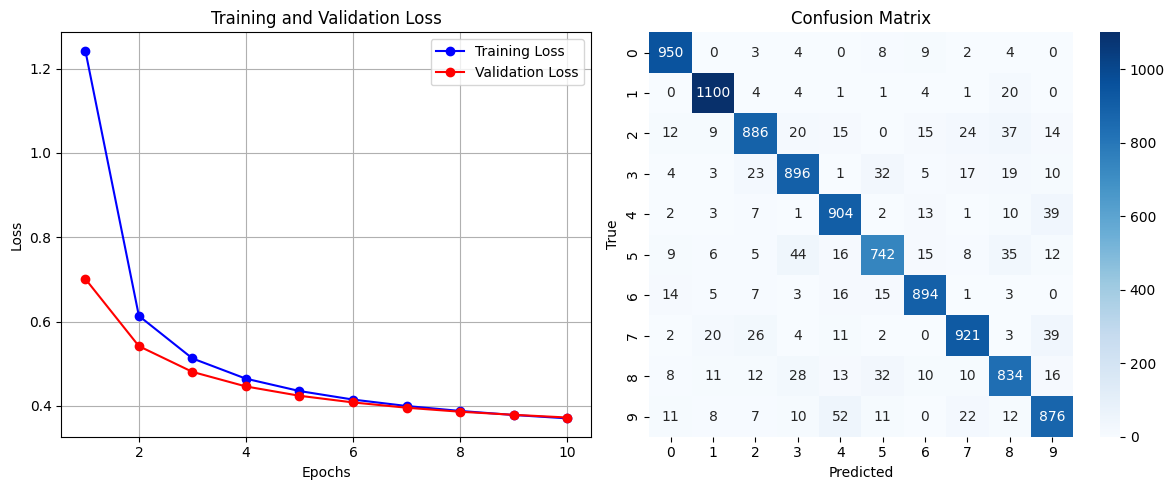

Đã vẽ và lưu đồ thị thành công vào file 'softmax_classifier_plots.png'!


In [9]:
json_filename = "softmax_classifier_results.json"
with open(json_filename, "w" if False else "r", encoding="utf-8") as f:
    data = json.load(f)

epochs = range(1, len(data['train_loss']) + 1)

#  Vẽ biểu đồ Training Loss vs Validation Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, data['train_loss'], 'b-o', label='Training Loss')
plt.plot(epochs, data['val_loss'], 'r-o', label='Validation Loss') 
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Tính toán và vẽ Ma trận nhầm lẫn (Confusion Matrix)
true_labels = data['confusion_matrix']['true_labels']
pred_labels = data['confusion_matrix']['pred_labels']
cm = confusion_matrix(true_labels, pred_labels)

plt.subplot(1, 2, 2)
# Tạo nhãn từ 0 đến 9 cho MNIST
classes = [str(i) for i in range(10)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.tight_layout()
# Lưu hình ảnh đồ thị ra file (🌟 Thay đổi tên file lưu cho đúng mô hình)
output_image = 'softmax_classifier_plots.png'
plt.savefig(output_image, dpi=300)
plt.show()

print(f"Đã vẽ và lưu đồ thị thành công vào file '{output_image}'!")